# Predicting the Sale Price of Bulldozers using Machine Learning

In this notebook we work through an end-to-end machine learning project: using the characteristics of bulldozers and the prices similar machines sold for in the past to predict the auction sale price of bulldozers sold in the future.

* **Inputs (features):** machine characteristics such as the year it was made, base model, model series, product size and enclosure, plus details of the sale such as the US state and the sale date.
* **Output (target):** the bulldozer's sale price in US dollars (`SalePrice`).

Because we are predicting a continuous number, this is a **regression** problem.

Because every sale has a date and the goal is to predict *future* sales from *past* ones, it is also a **time series** (forecasting) problem. This affects how we split the data: we train on older sales and validate on the most recent ones, never on a random split.

The data and the evaluation metric (root mean squared log error, RMSLE) come from the [Kaggle Blue Book for Bulldozers competition](https://www.kaggle.com/c/bluebook-for-bulldozers/overview).

The techniques used here are inspired by and adapted from [the fast.ai machine learning course](https://course18.fast.ai/ml).

**Notebook outline**

1. Problem definition, data, evaluation and features (the 6-step framework)
2. Load the data and explore it
3. Parse and engineer date features
4. Convert text to numbers and fill missing values
5. Split into training and validation sets by time
6. Model: baseline, hyperparameter tuning and the final model
7. Prepare the test set and make predictions
8. Results summary and next steps

## The 6-step machine learning framework

### 1. Problem definition

The question we are trying to answer is:

> How well can we predict the future sale price of a bulldozer, given its characteristics and previous examples of how much similar bulldozers have sold for?

A good price estimate helps dealers price their stock, helps buyers avoid overpaying and helps lenders value machines used as collateral.

### 2. Data

The [dataset from Kaggle](https://www.kaggle.com/c/bluebook-for-bulldozers/data) is historical auction sales data for bulldozers, including the model, size, configuration, where and when each machine was sold, and the price. Every row has a sale date, which is why this is a time series problem.

Kaggle provides three datasets:

1. **Train.csv**: historical sales up to the end of 2011 (about 400,000 rows with 50+ attributes, including `SalePrice`, the **target variable**).
2. **Valid.csv**: sales from 1 January 2012 to 30 April 2012 (about 12,000 rows with the same attributes as **Train.csv**).
3. **Test.csv**: sales from 1 May 2012 to November 2012 (12,457 rows, **without** `SalePrice`, because this is what we are trying to predict).

In this notebook we use **TrainAndValid.csv**, which combines Train.csv and Valid.csv: **412,698 sales from January 1989 to April 2012, with 53 columns**. Later we split it by year ourselves, keeping 2012 as the validation set.

> **Note:** You can download the `bluebook-for-bulldozers` dataset directly from Kaggle, or [from the course GitHub](https://github.com/mrdbourke/zero-to-mastery-ml/raw/refs/heads/master/data/bluebook-for-bulldozers.zip).

### 3. Evaluation

[Kaggle's evaluation metric for this competition is root mean squared log error (RMSLE)](https://www.kaggle.com/c/bluebook-for-bulldozers/overview/evaluation). The lower the RMSLE, the better.

$$\text{RMSLE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(\log(1+\hat{y}_i) - \log(1+y_i)\right)^2}$$

RMSLE suits this problem because:

* It measures **relative** error. Being \$5,000 off on a \$10,000 machine is penalised much more than being \$5,000 off on a \$100,000 machine.
* Sale prices are **right-skewed** (a few very expensive machines). Taking logs stops those machines from dominating the score.

Alongside RMSLE we also report **MAE** (mean absolute error, the average error in dollars, which is easy to explain) and **R²** (the share of price variation the model explains). We compare our RMSLE with the [Kaggle leaderboard](https://www.kaggle.com/c/bluebook-for-bulldozers/leaderboard), where the top scores are around 0.23.

### 4. Features

Features are the different columns of the data we use to make predictions. A **data dictionary** describes what each one means. Kaggle provides one for this dataset (`Data Dictionary.xlsx`). Some examples:

| Variable Name | Description  | Variable Type |
|------|-----|-----|
| SalesID   | unique identifier of a particular sale of a machine at auction  | Independent variable |
| MachineID  | identifier for a particular machine; machines may have multiple sales  | Independent variable |
| ModelID | identifier for a unique machine model (i.e. fiModelDesc) | Independent variable |
| datasource  | source of the sale record; some sources are more diligent about reporting attributes of the machine than others. Note that a particular datasource may report on multiple auctioneerIDs. | Independent variable |
| auctioneerID  | identifier of a particular auctioneer, i.e. company that sold the machine at auction. Not the same as datasource.  | Independent variable |
| YearMade  | year the machine was manufactured (1000 is used as a placeholder when the year is unknown) | Independent variable |
| MachineHoursCurrentMeter | current usage of the machine in hours at time of sale (saledate); null or 0 means no hours have been reported for that sale | Independent variable |
| UsageBand | value (low, medium, high) calculated comparing this particular Machine-Sale hours to average usage for the fiBaseModel; e.g. 'Low' means this machine has fewer hours given its lifespan relative to the average of fiBaseModel. | Independent variable |
| saledate   | time of sale | Independent variable |
| fiModelDesc  | description of a unique machine model (see ModelID); concatenation of fiBaseModel & fiSecondaryDesc & fiModelSeries & fiModelDescriptor  | Independent variable |
| state | US state in which the sale occurred | Independent variable |
| Drive_System | machine configuration; typically describes whether 2 or 4 wheel drive  | Independent variable |
| Enclosure  | machine configuration: does the machine have an enclosed cab or not | Independent variable |
| Forks  | machine configuration: attachment used for lifting  | Independent variable |
| Pad_Type | machine configuration: type of treads a crawler machine uses | Independent variable |
| Ride_Control  | machine configuration: optional feature on loaders to make the ride smoother | Independent variable |
| Transmission | machine configuration: describes type of transmission; typically automatic or manual | Independent variable |
| ... | ... | ... |
| SalePrice | cost of sale in USD | Target/dependent variable |

The full data dictionary is in `data/bluebook-for-bulldozers/Data Dictionary.xlsx`, on the [Kaggle competition page](https://www.kaggle.com/c/bluebook-for-bulldozers/download/Bnl6RAHA0enbg0UfAvGA%2Fversions%2FwBG4f35Q8mAbfkzwCeZn%2Ffiles%2FData%20Dictionary.xlsx) (account required) or [on Google Sheets](https://docs.google.com/spreadsheets/d/18ly-bLR8sbDJLITkWG7ozKm8l3RyieQ2Fpgix-beSYI/edit?usp=sharing).

Our plan: load and explore the data, prepare it for modelling, build a baseline model, then improve it and compare the score with the competition.

## 1. Import the tools and the data

We start by importing pandas (data handling), NumPy (numerical operations), matplotlib (plotting) and scikit-learn (machine learning).

In [136]:
# Import the data analysis and machine learning tools
import pandas as pd               # data loading and manipulation
import numpy as np                # numerical operations
import matplotlib
import matplotlib.pyplot as plt   # plotting
import sklearn                    # machine learning models and metrics

# Print the library versions used (if your versions are the same or newer, the code should work)
print(f"pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"matplotlib version: {matplotlib.__version__}") 

pandas version: 3.0.6
NumPy version: 2.5.4
matplotlib version: 3.11.2


In [2]:
# Load the combined training + validation data (412,698 sales, 1989 to April 2012)
# low_memory=False makes pandas read the whole file before guessing column types,
# which avoids mixed-type warnings on this large file
df = pd.read_csv("../data/raw/bluebook-for-bulldozers/TrainAndValid.csv",low_memory=False)

### First look at the data

`df.info()` shows each column's name, data type and how many non-missing values it has. Things to notice:

* 412,698 rows and 53 columns;
* many columns are text (`object` / `str`), which models can't use directly;
* many columns have far fewer non-missing values than rows, so there's a lot of missing data;
* `saledate` is stored as text, not as a date.

In [3]:
# Overview: column names, data types and number of non-missing values per column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 53 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   str    
 9   saledate                  412698 non-null  str    
 10  fiModelDesc               412698 non-null  str    
 11  fiBaseModel               412698 non-null  str    
 12  fiSecondaryDesc           271971 non-null  str    
 13  fiModelSeries             58667 non-null   str    
 14 

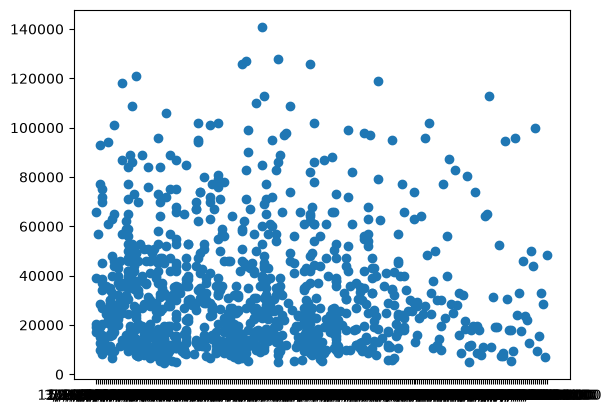

In [4]:
# Plot sale price against sale date for the first 1,000 rows
# saledate is still text at this point, so the x-axis can't be read as a timeline
fig, ax = plt.subplots()
ax.scatter(df["saledate"][:1000], df["SalePrice"][:1000])

<Axes: ylabel='Frequency'>

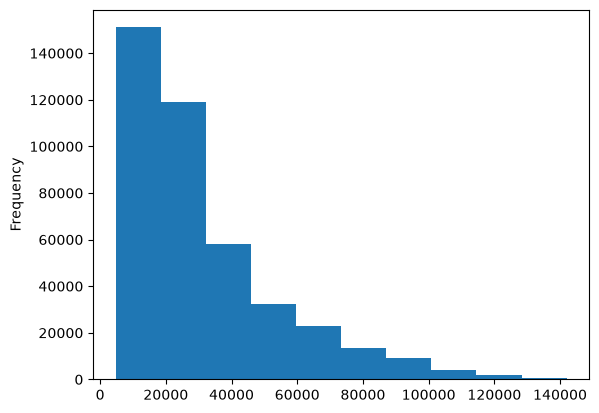

In [5]:
# Distribution of sale prices: most sales are at the lower end with a long tail
# of expensive machines (right-skewed), one reason the competition uses RMSLE
df.SalePrice.plot.hist()

## Parsing dates

When we read the CSV above, `saledate` was loaded as plain **text** (`object` / `str` dtype), so pandas doesn't know it is a date. That is why the scatter plot's x-axis is unreadable: every date string is treated as a separate label.

To fix this we re-read the file with the `parse_dates` parameter, which converts `saledate` into a proper `datetime64` column. Then we can sort by date and extract parts of it (year, month, day, ...) as features.

In [6]:
# Look at the raw saledate values: they are stored as text, not dates
df.saledate[:1000]

0      11/16/2006 0:00
1       3/26/2004 0:00
2       2/26/2004 0:00
3       5/19/2011 0:00
4       7/23/2009 0:00
            ...       
995     7/16/2009 0:00
996     6/14/2007 0:00
997     9/22/2005 0:00
998     7/28/2005 0:00
999     6/16/2011 0:00
Name: saledate, Length: 1000, dtype: str

In [7]:
# Import the data again, this time telling pandas to parse saledate as a datetime
df = pd.read_csv("../data/raw/bluebook-for-bulldozers/TrainAndValid.csv",
                 low_memory=False,
                parse_dates=["saledate"])

In [8]:
# Confirm saledate is now a datetime type (datetime64)
df.saledate.dtype

dtype('<M8[us]')

In [9]:
# The values are now proper timestamps
df.saledate[:1000]

0     2006-11-16
1     2004-03-26
2     2004-02-26
3     2011-05-19
4     2009-07-23
         ...    
995   2009-07-16
996   2007-06-14
997   2005-09-22
998   2005-07-28
999   2011-06-16
Name: saledate, Length: 1000, dtype: datetime64[us]

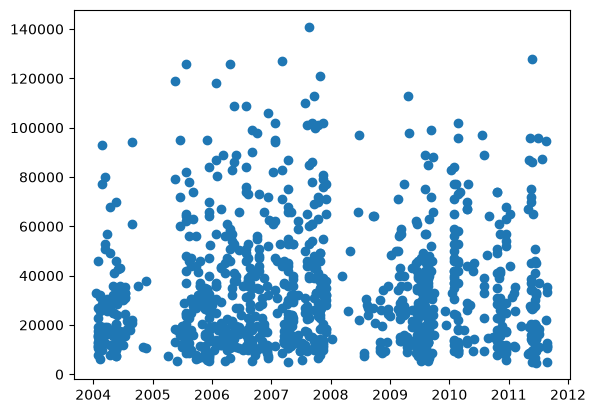

In [10]:
# Re-draw the scatter plot: with real dates the x-axis is now a readable timeline
fig, ax = plt.subplots()
ax.scatter(df["saledate"][:1000], df["SalePrice"][:1000])

In [11]:
# First five rows of the data
df.head()

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
0,1139246,66000.0,999089,3157,121,3.0,2004,68.0,Low,2006-11-16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139248,57000.0,117657,77,121,3.0,1996,4640.0,Low,2004-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
2,1139249,10000.0,434808,7009,121,3.0,2001,2838.0,High,2004-02-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1139251,38500.0,1026470,332,121,3.0,2001,3486.0,High,2011-05-19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139253,11000.0,1057373,17311,121,3.0,2007,722.0,Medium,2009-07-23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Transpose (.T) to see all 53 columns as rows, which is easier to read
df.head().T

,0,1,2,3,4
SalesID,1139246,1139248,1139249,1139251,1139253
SalePrice,66000.0,57000.0,10000.0,38500.0,11000.0
MachineID,999089,117657,434808,1026470,1057373
ModelID,3157,77,7009,332,17311
datasource,121,121,121,121,121
auctioneerID,3.0,3.0,3.0,3.0,3.0
YearMade,2004,1996,2001,2001,2007
MachineHoursCurrentMeter,68.0,4640.0,2838.0,3486.0,722.0
UsageBand,Low,Low,High,High,Medium
saledate,2006-11-16 00:00:00,2004-03-26 00:00:00,2004-02-26 00:00:00,2011-05-19 00:00:00,2009-07-23 00:00:00


In [13]:
# The data isn't in date order yet
df.saledate.head(20)

0    2006-11-16
1    2004-03-26
2    2004-02-26
3    2011-05-19
4    2009-07-23
5    2008-12-18
6    2004-08-26
7    2005-11-17
8    2009-08-27
9    2007-08-09
10   2008-08-21
11   2006-08-24
12   2005-10-20
13   2006-01-26
14   2006-01-03
15   2006-11-16
16   2007-06-14
17   2010-01-28
18   2006-03-09
19   2005-11-17
Name: saledate, dtype: datetime64[us]

### Sort the DataFrame by `saledate`

With time series data it's a good idea to sort by date. It keeps events in the order they happened and makes the time-based train/validation split later on clean and easy to check.

In [14]:
# Sort all rows by sale date, oldest first (inplace=True changes df directly)
df.sort_values(by=["saledate"], inplace=True)

In [15]:
# Check the dates are now in order
df.saledate.head(20)

205615   1989-01-17
274835   1989-01-31
141296   1989-01-31
212552   1989-01-31
62755    1989-01-31
54653    1989-01-31
81383    1989-01-31
204924   1989-01-31
135376   1989-01-31
113390   1989-01-31
113394   1989-01-31
116419   1989-01-31
32138    1989-01-31
127610   1989-01-31
76171    1989-01-31
127000   1989-01-31
128130   1989-01-31
127626   1989-01-31
55455    1989-01-31
55454    1989-01-31
Name: saledate, dtype: datetime64[us]

In [16]:
# Make a copy so we can change the data freely and still have the original df to fall back on
df_tmp = df.copy()

In [17]:
# Check the copy looks the same as the original
df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
auctioneerID,18.0,99.0,99.0,99.0,99.0
YearMade,1974,1980,1978,1980,1984
MachineHoursCurrentMeter,NaN,NaN,NaN,NaN,NaN
UsageBand,NaN,NaN,NaN,NaN,NaN
saledate,1989-01-17 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00


In [18]:
# The original df is still sorted by date
df.saledate.head(20)

205615   1989-01-17
274835   1989-01-31
141296   1989-01-31
212552   1989-01-31
62755    1989-01-31
54653    1989-01-31
81383    1989-01-31
204924   1989-01-31
135376   1989-01-31
113390   1989-01-31
113394   1989-01-31
116419   1989-01-31
32138    1989-01-31
127610   1989-01-31
76171    1989-01-31
127000   1989-01-31
128130   1989-01-31
127626   1989-01-31
55455    1989-01-31
55454    1989-01-31
Name: saledate, dtype: datetime64[us]

## Feature engineering: add date features from `saledate`

A Random Forest can't use a `datetime` column directly. Instead, we break `saledate` into numeric parts the model *can* use:

| New column | Meaning | Why it might help |
|---|---|---|
| `saleYear` | year of sale | captures market trends and economic cycles (e.g. the 2009 recession) |
| `saleMonth` | month (1–12) | captures seasonality |
| `saleDay` | day of the month | |
| `saleDayOfWeek` | day of the week (0 = Monday) | auctions cluster on certain weekdays |
| `saleDayOfYear` | day of the year (1–366) | finer-grained seasonality |

The next few cells show how the `.dt` accessor works on a single row first.

In [19]:
# Example: extract the year from the first row's sale date
df_tmp[:1].saledate.dt.year

205615    1989
Name: saledate, dtype: int32

In [20]:
# Example: extract the day of the month
df_tmp[:1].saledate.dt.day

205615    17
Name: saledate, dtype: int32

In [21]:
# The full timestamp the values above came from
df_tmp[:1].saledate

205615   1989-01-17
Name: saledate, dtype: datetime64[us]

In [22]:
# Add date features for saledate (used by the model instead of the raw timestamp)
df_tmp["saleYear"] = df_tmp.saledate.dt.year
df_tmp["saleMonth"] = df_tmp.saledate.dt.month
df_tmp["saleDay"] = df_tmp.saledate.dt.day
df_tmp["saleDayOfWeek"] = df_tmp.saledate.dt.dayofweek    # 0 = Monday, 6 = Sunday
df_tmp["saleDayOfYear"] = df_tmp.saledate.dt.dayofyear    # 1 to 366

In [23]:
# The five new date columns appear at the end
df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
auctioneerID,18.0,99.0,99.0,99.0,99.0
YearMade,1974,1980,1978,1980,1984
MachineHoursCurrentMeter,NaN,NaN,NaN,NaN,NaN
UsageBand,NaN,NaN,NaN,NaN,NaN
saledate,1989-01-17 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00,1989-01-31 00:00:00


In [24]:
# Now that the date information is in separate numeric columns, drop the original saledate
df_tmp.drop("saledate", axis=1, inplace=True)

In [25]:
# Number of sales per US state (Florida and Texas have the most)
df_tmp.state.value_counts()

state
Florida           67320
Texas             53110
California        29761
Washington        16222
Georgia           14633
Maryland          13322
Mississippi       13240
Ohio              12369
Illinois          11540
Colorado          11529
New Jersey        11156
North Carolina    10636
Tennessee         10298
Alabama           10292
Pennsylvania      10234
South Carolina     9951
Arizona            9364
New York           8639
Connecticut        8276
Minnesota          7885
Missouri           7178
Nevada             6932
Louisiana          6627
Kentucky           5351
Maine              5096
Indiana            4124
Arkansas           3933
New Mexico         3631
Utah               3046
Unspecified        2801
Wisconsin          2745
New Hampshire      2738
Virginia           2353
Idaho              2025
Oregon             1911
Michigan           1831
Wyoming            1672
Montana            1336
Iowa               1336
Oklahoma           1326
Nebraska            866
West Virgi

## 5. Modelling

We now have date features, so let's try fitting a model.

We use `RandomForestRegressor` from scikit-learn because it:

* works well on tabular data with mixed feature types,
* needs no feature scaling,
* captures non-linear effects and interactions between features (for example, age may matter more for some machine types),
* gives feature importances that help explain the model.

> **Expect the next model to fail.** Most of the columns are still text (e.g. `UsageBand` = `'Low'`), and scikit-learn models only accept numbers. Running it anyway shows us exactly what needs fixing.

In [26]:
# Look at the data we are about to model
df_tmp.head()

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayOfWeek,saleDayOfYear
205615,1646770,9500.0,1126363,8434,132,18.0,1974,NaN,NaN,TD20,...,None or Unspecified,Straight,None or Unspecified,NaN,NaN,1989,1,17,1,17
274835,1821514,14000.0,1194089,10150,132,99.0,1980,NaN,NaN,A66,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31
141296,1505138,50000.0,1473654,4139,132,99.0,1978,NaN,NaN,D7G,...,None or Unspecified,Straight,None or Unspecified,NaN,NaN,1989,1,31,1,31
212552,1671174,16000.0,1327630,8591,132,99.0,1980,NaN,NaN,A62,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31
62755,1329056,22000.0,1336053,4089,132,99.0,1984,NaN,NaN,D3B,...,None or Unspecified,PAT,Lever,NaN,NaN,1989,1,31,1,31


In [27]:
# Number of rows (sales)
len(df_tmp)

412698

In [28]:
# First attempt at fitting a model on the data as it is
# This is EXPECTED TO FAIL: many columns still contain text (e.g. UsageBand = 'Low')
# and missing values, and scikit-learn models only accept numbers
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_jobs=-1,          # use all CPU cores
                              random_state=42)    # make results reproducible

model.fit(df_tmp.drop("SalePrice", axis=1), df_tmp["SalePrice"])

ValueError: could not convert string to float: 'Low'

### Why did the model fail?

The error `ValueError: could not convert string to float: 'Low'` means scikit-learn found **text** in the data. It also can't handle missing values (`NaN`). The next two cells show the column types and the number of missing values in each column.

In [29]:
# Check the data types: many columns are text (str/object), which the model can't use
df_tmp.info()

<class 'pandas.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   str    
 9   fiModelDesc               412698 non-null  str    
 10  fiBaseModel               412698 non-null  str    
 11  fiSecondaryDesc           271971 non-null  str    
 12  fiModelSeries             58667 non-null   str    
 13  fiModelDescriptor         74816 non-null   str    
 14 

In [30]:
# Number of missing values in each column
df_tmp.isna().sum()

SalesID                          0
SalePrice                        0
MachineID                        0
ModelID                          0
datasource                       0
auctioneerID                 20136
YearMade                         0
MachineHoursCurrentMeter    265194
UsageBand                   339028
fiModelDesc                      0
fiBaseModel                      0
fiSecondaryDesc             140727
fiModelSeries               354031
fiModelDescriptor           337882
ProductSize                 216605
fiProductClassDesc               0
state                            0
ProductGroup                     0
ProductGroupDesc                 0
Drive_System                305611
Enclosure                      334
Forks                       214983
Pad_Type                    331602
Ride_Control                259970
Stick                       331602
Transmission                224691
Turbocharged                331602
Blade_Extension             386715
Blade_Width         

### Convert strings into pandas categories

The model failed with `ValueError: could not convert string to float: 'Low'` because many columns contain text, and the output of `df_tmp.isna().sum()` above shows many columns also have missing values. Before modelling, every column must be **numeric** and contain **no missing values**.

One way to turn text into numbers is to convert each text column into a pandas `category`. Each category value then gets an integer code behind the scenes (accessible with `.cat.codes`), which we use later.

First we find which columns contain strings.

In [31]:
# Check whether a column contains strings (text), e.g. UsageBand
pd.api.types.is_string_dtype(df_tmp["UsageBand"])

True

In [32]:
# List every column that contains strings
for label, content in df_tmp.items():
    if pd.api.types.is_string_dtype(content):
        print(label)

UsageBand
fiModelDesc
fiBaseModel
fiSecondaryDesc
fiModelSeries
fiModelDescriptor
ProductSize
fiProductClassDesc
state
ProductGroup
ProductGroupDesc
Drive_System
Enclosure
Forks
Pad_Type
Ride_Control
Stick
Transmission
Turbocharged
Blade_Extension
Blade_Width
Enclosure_Type
Engine_Horsepower
Hydraulics
Pushblock
Ripper
Scarifier
Tip_Control
Tire_Size
Coupler
Coupler_System
Grouser_Tracks
Hydraulics_Flow
Track_Type
Undercarriage_Pad_Width
Stick_Length
Thumb
Pattern_Changer
Grouser_Type
Backhoe_Mounting
Blade_Type
Travel_Controls
Differential_Type
Steering_Controls


In [33]:
# Convert every string column into an ordered pandas category
# Each category gets a hidden integer code we can use later
for label, content in df_tmp.items():
    if pd.api.types.is_string_dtype(content):
        df_tmp[label] = content.astype("category").cat.as_ordered()

In [34]:
# Check that the string columns are now 'category' type
df_tmp.info()

<class 'pandas.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         74816 non-null

In [35]:
# Look at one category column: the list of distinct states
df_tmp.state.cat.categories

Index(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado',
       'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina',
       'South Dakota', 'Tennessee', 'Texas', 'Unspecified', 'Utah', 'Vermont',
       'Virginia', 'Washington', 'Washington DC', 'West Virginia', 'Wisconsin',
       'Wyoming'],
      dtype='str')

In [36]:
# Sales per state (the text values are unchanged; only the storage type changed)
df_tmp.state.value_counts()

state
Florida           67320
Texas             53110
California        29761
Washington        16222
Georgia           14633
Maryland          13322
Mississippi       13240
Ohio              12369
Illinois          11540
Colorado          11529
New Jersey        11156
North Carolina    10636
Tennessee         10298
Alabama           10292
Pennsylvania      10234
South Carolina     9951
Arizona            9364
New York           8639
Connecticut        8276
Minnesota          7885
Missouri           7178
Nevada             6932
Louisiana          6627
Kentucky           5351
Maine              5096
Indiana            4124
Arkansas           3933
New Mexico         3631
Utah               3046
Unspecified        2801
Wisconsin          2745
New Hampshire      2738
Virginia           2353
Idaho              2025
Oregon             1911
Michigan           1831
Wyoming            1672
Iowa               1336
Montana            1336
Oklahoma           1326
Nebraska            866
West Virgi

In [37]:
# The integer code behind each state (missing values would be -1)
df_tmp.state.cat.codes

205615    43
274835     8
141296     8
212552     8
62755      8
          ..
410879     4
412476     4
411927     4
407124     4
409203     4
Length: 412698, dtype: int8

In [38]:
# Percentage of missing values in each column
df_tmp.isnull().sum()/len(df_tmp)*100

SalesID                      0.000000
SalePrice                    0.000000
MachineID                    0.000000
ModelID                      0.000000
datasource                   0.000000
auctioneerID                 4.879113
YearMade                     0.000000
MachineHoursCurrentMeter    64.258610
UsageBand                   82.149174
fiModelDesc                  0.000000
fiBaseModel                  0.000000
fiSecondaryDesc             34.099269
fiModelSeries               85.784520
fiModelDescriptor           81.871490
ProductSize                 52.485110
fiProductClassDesc           0.000000
state                        0.000000
ProductGroup                 0.000000
ProductGroupDesc             0.000000
Drive_System                74.051970
Enclosure                    0.080931
Forks                       52.092087
Pad_Type                    80.349796
Ride_Control                62.992794
Stick                       80.349796
Transmission                54.444412
Turbocharged

### Save the partially preprocessed data

Before filling missing values, we export `df_tmp` (date features added, text converted to categories) to CSV as a checkpoint. If something goes wrong later, we can reload from here instead of starting from scratch.

> **Note:** saving to CSV turns the category columns back into plain text, so if you reload this file you need to repeat the category conversion.

In [39]:
# Export the current df_tmp as a backup checkpoint in case anything goes wrong later
df_tmp.to_csv("../data/processed/train_tmp.csv", index=False)

In [40]:
# Check the data is unchanged after saving
df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
auctioneerID,18.0,99.0,99.0,99.0,99.0
YearMade,1974,1980,1978,1980,1984
MachineHoursCurrentMeter,NaN,NaN,NaN,NaN,NaN
UsageBand,NaN,NaN,NaN,NaN,NaN
fiModelDesc,TD20,A66,D7G,A62,D3B


## Fill missing values

The percentages above show a lot of missing data: for example, `auctioneerID` is about 5% missing, `MachineHoursCurrentMeter` about 64%, and several machine configuration columns over 90%. Many of these attributes only apply to certain machine types (a machine without a blade has no `Blade_Width`).

We handle numeric and text (categorical) columns separately.

### Fill numeric missing values first

For each numeric column that has gaps we:

1. add a `<column>_is_missing` True/False column, because the fact that a value was missing may itself help predict the price;
2. fill the gaps with the column's **median**. The median is used rather than the mean because the data is skewed and has outliers (e.g. very high machine hours), and the median is not pulled by extreme values.

In [41]:
# List the numeric columns
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        print(label)

SalesID
SalePrice
MachineID
ModelID
datasource
auctioneerID
YearMade
MachineHoursCurrentMeter
saleYear
saleMonth
saleDay
saleDayOfWeek
saleDayOfYear


In [42]:
# Spot-check one numeric column
df_tmp.ModelID

205615     8434
274835    10150
141296     4139
212552     8591
62755      4089
          ...  
410879     5266
412476    19330
411927    17244
407124     3357
409203     4701
Name: ModelID, Length: 412698, dtype: int64

In [43]:
# List the numeric columns that have missing values
# (auctioneerID and MachineHoursCurrentMeter)
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            print(label)

auctioneerID
MachineHoursCurrentMeter


In [44]:
# Fill missing numeric values with the median (not the mean: the median isn't pulled by outliers)
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            # Add a True/False column recording whether the value was missing
            df_tmp[label+"_is_missing"] = pd.isnull(content)
            # Fill missing numeric values with the column's median
            df_tmp[label] = content.fillna(content.median())

In [45]:
# Check that no numeric column has missing values left.
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            print(label)
            # Nothing is printed, because every numeric gap has been filled with the median

In [46]:
# How many auctioneerID values were missing (True) before filling
df_tmp.auctioneerID_is_missing.value_counts()

auctioneerID_is_missing
False    392562
True      20136
Name: count, dtype: int64

In [47]:
# The new _is_missing columns appear at the end
df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
auctioneerID,18.0,99.0,99.0,99.0,99.0
YearMade,1974,1980,1978,1980,1984
MachineHoursCurrentMeter,0.0,0.0,0.0,0.0,0.0
UsageBand,NaN,NaN,NaN,NaN,NaN
fiModelDesc,TD20,A66,D7G,A62,D3B


### Fill missing categorical values and turn categories into numbers

For each non-numeric (category) column we:

1. add a `<column>_is_missing` True/False column, as we did for numeric columns;
2. replace the text with its **category code + 1**.

Why **+1**? pandas gives missing values the code **-1**. Adding 1 shifts every code up by one, so missing values become **0** and real categories start at **1**. This fills the gaps and converts the text to numbers in one step.

We use category codes (label encoding) rather than one-hot encoding because some columns have thousands of different values (e.g. `fiModelDesc`; there are 5,281 distinct `ModelID`s). One-hot encoding would create thousands of extra columns, while tree models split integer codes well.

In [48]:
# List the columns that are not numeric (the category columns still to convert)
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        print(label)

UsageBand
fiModelDesc
fiBaseModel
fiSecondaryDesc
fiModelSeries
fiModelDescriptor
ProductSize
fiProductClassDesc
state
ProductGroup
ProductGroupDesc
Drive_System
Enclosure
Forks
Pad_Type
Ride_Control
Stick
Transmission
Turbocharged
Blade_Extension
Blade_Width
Enclosure_Type
Engine_Horsepower
Hydraulics
Pushblock
Ripper
Scarifier
Tip_Control
Tire_Size
Coupler
Coupler_System
Grouser_Tracks
Hydraulics_Flow
Track_Type
Undercarriage_Pad_Width
Stick_Length
Thumb
Pattern_Changer
Grouser_Type
Backhoe_Mounting
Blade_Type
Travel_Controls
Differential_Type
Steering_Controls


In [49]:
# Example: what pd.Categorical gives for the state column
pd.Categorical(df_tmp["state"])

['Texas', 'Florida', 'Florida', 'Florida', 'Florida', ..., 'California', 'California', 'California', 'California', 'California']
Length: 412698
Categories (53, str): ['Alabama' < 'Alaska' < 'Arizona' < 'Arkansas' ... 'Washington DC' < 'West Virginia' < 'Wisconsin' < 'Wyoming']

In [50]:
# Its data type lists the categories in order
pd.Categorical(df_tmp["state"]).dtype

CategoricalDtype(categories=['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
                  'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia',
                  'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas',
                  'Kentucky', 'Louisiana', 'Maine', 'Maryland',
                  'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi',
                  'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire',
                  'New Jersey', 'New Mexico', 'New York', 'North Carolina',
                  'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania',
                  'Puerto Rico', 'Rhode Island', 'South Carolina',
                  'South Dakota', 'Tennessee', 'Texas', 'Unspecified', 'Utah',
                  'Vermont', 'Virginia', 'Washington', 'Washington DC',
                  'West Virginia', 'Wisconsin', 'Wyoming'],
, ordered=True, categories_dtype=str)

In [51]:
# Turn categorical variables into numbers and fill their missing values
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        # Add a True/False column recording whether the value was missing
        df_tmp[label+"_is_missing"] = pd.isnull(content)
        # Replace text with its category code + 1 (missing values: -1 + 1 = 0)
        df_tmp[label] = pd.Categorical(content).codes + 1

In [53]:
# state is now numbers; pd.Categorical on integer codes simply maps them to 0, 1, 2, ...
pd.Categorical(df_tmp["state"]).codes

array([43,  8,  8, ...,  4,  4,  4], shape=(412698,), dtype=int8)

In [54]:
# UsageBand is now numbers too (0 = was missing)
pd.Categorical(df_tmp["UsageBand"]).codes + 1

array([1, 1, 1, ..., 1, 1, 1], shape=(412698,), dtype=int8)

In [55]:
# Every column should now be numeric (int, float or bool)
df_tmp.info()

<class 'pandas.DataFrame'>
Index: 412698 entries, 205615 to 409203
Columns: 103 entries, SalesID to Steering_Controls_is_missing
dtypes: bool(46), float64(3), int16(4), int32(5), int64(5), int8(40)
memory usage: 73.2 MB


In [56]:
# Look at the fully numeric data
df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
...,...,...,...,...,...
Backhoe_Mounting_is_missing,False,True,False,True,False
Blade_Type_is_missing,False,True,False,True,False
Travel_Controls_is_missing,False,True,False,True,False
Differential_Type_is_missing,True,False,True,False,True


In [57]:
# Confirm there are no missing values left (every count should be 0)
df_tmp.isna().sum()

SalesID                         0
SalePrice                       0
MachineID                       0
ModelID                         0
datasource                      0
                               ..
Backhoe_Mounting_is_missing     0
Blade_Type_is_missing           0
Travel_Controls_is_missing      0
Differential_Type_is_missing    0
Steering_Controls_is_missing    0
Length: 103, dtype: int64

In [58]:
# Final check of the model-ready data
df_tmp.head()

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Undercarriage_Pad_Width_is_missing,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing
205615,1646770,9500.0,1126363,8434,132,18.0,1974,0.0,0,4593,...,True,True,True,True,True,False,False,False,True,True
274835,1821514,14000.0,1194089,10150,132,99.0,1980,0.0,0,1820,...,True,True,True,True,True,True,True,True,False,False
141296,1505138,50000.0,1473654,4139,132,99.0,1978,0.0,0,2348,...,True,True,True,True,True,False,False,False,True,True
212552,1671174,16000.0,1327630,8591,132,99.0,1980,0.0,0,1819,...,True,True,True,True,True,True,True,True,False,False
62755,1329056,22000.0,1336053,4089,132,99.0,1984,0.0,0,2119,...,True,True,True,True,True,False,False,False,True,True


In [59]:
# Import the model again (already imported above; repeated so this section can run on its own)
from sklearn.ensemble import RandomForestRegressor

In [60]:
%%time
# Now that all data is numeric with no missing values, the model can be fitted
# Instantiate the model
model = RandomForestRegressor(n_jobs=-1,
                              random_state=42)
# Fit the model on ALL rows (including 2012); we only use this to check fitting works
model.fit(df_tmp.drop("SalePrice", axis=1), df_tmp["SalePrice"])

CPU times: total: 24min
Wall time: 1min 30s


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [61]:
# Score the model (R²) on the SAME data it was trained on
# The very high score is misleading: the model has already seen these rows.
# A fair score needs separate validation data (next section).
model.score(df_tmp.drop("SalePrice", axis=1), df_tmp["SalePrice"])

0.9875468079970562

## Split the data into training and validation sets

The score above (R² ≈ 0.99) looks excellent, but it is **misleading**: the model was trained and scored on the *same* rows, so it is being tested on data it has already seen.

To get an honest estimate we need data the model has never seen. Because this is a time series problem, we split by **time**, mimicking how the model would really be used (predicting future sales from past ones):

* **Training set:** all sales before 2012 (401,125 rows)
* **Validation set:** sales from 2012 (11,573 rows, January to April)

A random split would mix 2012 sales into training, letting the model "see the future" and making the score look better than it really is.

In [62]:
# The year of each sale
df_tmp.saleYear

205615    1989
274835    1989
141296    1989
212552    1989
62755     1989
          ... 
410879    2012
412476    2012
411927    2012
407124    2012
409203    2012
Name: saleYear, Length: 412698, dtype: int32

In [63]:
# Number of sales per year (sorted by count)
df_tmp.saleYear.value_counts()

saleYear
2009    43849
2008    39767
2011    35197
2010    33390
2007    32208
2006    21685
2005    20463
2004    19879
2001    17594
2000    17415
2002    17246
2003    15254
1998    13046
1999    12793
2012    11573
1997     9785
1996     8829
1995     8530
1994     7929
1993     6303
1992     5519
1991     5109
1989     4806
1990     4529
Name: count, dtype: int64

In [89]:
# Number of sales per year in date order: 2012 only covers January to April
df_tmp.saleYear.value_counts().sort_index()

saleYear
1989     4806
1990     4529
1991     5109
1992     5519
1993     6303
1994     7929
1995     8530
1996     8829
1997     9785
1998    13046
1999    12793
2000    17415
2001    17594
2002    17246
2003    15254
2004    19879
2005    20463
2006    21685
2007    32208
2008    39767
2009    43849
2010    33390
2011    35197
2012    11573
Name: count, dtype: int64

In [64]:
# Split by time: 2012 sales become the validation set, everything earlier is for training
df_val = df_tmp[df_tmp.saleYear == 2012]
df_train = df_tmp[df_tmp.saleYear !=2012]

len(df_val), len(df_train)

(11573, 401125)

In [65]:
# Split each set into features (X) and target (y = SalePrice)
X_train, y_train = df_train.drop("SalePrice", axis=1), df_train.SalePrice
X_valid, y_valid = df_val.drop("SalePrice", axis=1), df_val.SalePrice

X_train.shape, y_train.shape, X_valid.shape, y_valid.shape

((401125, 102), (401125,), (11573, 102), (11573,))

In [66]:
# The training target: sale prices in US dollars
y_train

205615     9500.0
274835    14000.0
141296    50000.0
212552    16000.0
62755     22000.0
           ...   
393098    29000.0
400217    11000.0
400302    11000.0
400393    18000.0
393123    13500.0
Name: SalePrice, Length: 401125, dtype: float64

### Build an evaluation function

`show_scores()` reports three metrics on both the training and the validation set:

* **MAE**: average error in dollars
* **RMSLE**: the competition metric (lower is better)
* **R²**: share of the variation in price that the model explains (1.0 is perfect)

Comparing training with validation scores tells us how well the model fits:

* training error much lower than validation error → **overfitting** (memorising the training data);
* both errors high and close together → **underfitting** (model too simple).

In [68]:
# Evaluation metrics (the competition uses RMSLE)
from sklearn.metrics import root_mean_squared_log_error, mean_absolute_error, r2_score

# Evaluate a model on both the training and the validation set.
# A big gap between training and validation scores is a sign of overfitting.
def show_scores(model):
    train_preds = model.predict(X_train)
    val_preds = model.predict(X_valid)
    scores = {"Training MAE": mean_absolute_error(y_train, train_preds),
              "Valid MAE": mean_absolute_error(y_valid, val_preds),
              "Training RMSLE": root_mean_squared_log_error(y_train, train_preds),
              "Valid RMSLE": root_mean_squared_log_error(y_valid, val_preds),
              "Training R^2": r2_score(y_train, train_preds),
              "Valid R^2": r2_score(y_valid, val_preds)}
    return scores

### Speed up experiments by training on a subset

Fitting a Random Forest on all 401,125 training rows takes over a minute (and much more CPU time), which is too slow to try lots of settings.

Setting `max_samples=10000` means each tree is trained on a random sample of only 10,000 rows. This makes experiments much faster, at the cost of some accuracy. Once we have chosen good hyperparameters, we retrain on all the data.

In [69]:
# Training on all ~400,000 rows is too slow for trying lots of settings,
# so each tree only sees a random sample of 10,000 rows (max_samples=10000)
model = RandomForestRegressor(n_jobs=-1,
                              random_state=42,
                              max_samples=10000)

In [70]:
%time
# Note: %time on a line by itself times nothing; put %%time as the cell's first line to time the whole cell.
# Limiting each tree to 10,000 rows makes fitting much faster
model.fit(X_train, y_train)

CPU times: total: 0 ns
Wall time: 6.68 μs


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",10000
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", th

In [71]:
# Baseline scores for the quick model (valid RMSLE ≈ 0.294)
show_scores(model)

{'Training MAE': 5561.298809224058,
 'Valid MAE': 7177.26365505919,
 'Training RMSLE': 0.25774537825697696,
 'Valid RMSLE': 0.29362638671089003,
 'Training R^2': 0.8606658995199188,
 'Valid R^2': 0.8320374995090507}

In [73]:
### Hyperparameter tuning with RandomizedSearchCV
%time
# RandomizedSearchCV tries random combinations from the grid (n_iter of them) instead of
# every combination like GridSearchCV, so it's much faster on a big search space
from sklearn.model_selection import RandomizedSearchCV

# Different RandomForestRegressor hyperparameters to sample from
rf_grid = {"n_estimators": np.arange(10, 100, 10),       # number of trees
           "max_depth": [None, 3, 5, 10],                # maximum depth of each tree
           "min_samples_leaf": np.arange(1, 20, 2),      # minimum rows in a leaf
           "max_features": [0.5, 1, "sqrt", None],       # features considered at each split
           "max_samples": [10000]}                       # rows sampled per tree (keeps it fast)

# Instantiate the RandomizedSearchCV model
# n_iter=5: try 5 random combinations; cv=5: 5-fold cross-validation on the training data
# (note: these folds are not time-ordered; sklearn's TimeSeriesSplit would respect the dates)
rs_model = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1,
                                                    random_state=42),
                              param_distributions=rf_grid,
                              n_iter=5,
                              cv=5,
                              verbose=True)
# Fit the RandomizedSearchCV model (5 combinations x 5 folds = 25 fits)
rs_model.fit(X_train, y_train)

CPU times: total: 0 ns
Wall time: 3.58 μs
Fitting 5 folds for each of 5 candidates, totalling 25 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 3, ...], 'max_features': [0.5, 1, ...], 'max_samples': [10000], 'min_samples_leaf': array([ 1, 3..., 15, 17, 19]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and p

In [74]:
# The best combination found in this short search
rs_model.best_params_

{'n_estimators': np.int64(60),
 'min_samples_leaf': np.int64(5),
 'max_samples': 10000,
 'max_features': None,
 'max_depth': 10}

In [75]:
# Evaluate the best model from the search
# It is worse than the quick model (valid RMSLE ≈ 0.316 vs 0.294): with only 5 tries the search
# picked max_depth=10, which limits each tree too much, so the model underfits
show_scores(rs_model)

{'Training MAE': 6504.5142694611495,
 'Valid MAE': 7904.718773920244,
 'Training RMSLE': 0.29227981950263726,
 'Valid RMSLE': 0.31603332784735366,
 'Training R^2': 0.8156470020914006,
 'Valid R^2': 0.7940688364570506}

## Train a model with the best hyperparameters

The hyperparameters below were found after running `RandomizedSearchCV` for **100 iterations** (an earlier, longer run than the 5-iteration search above, which is kept short so the notebook runs quickly).

What each setting does:

| Hyperparameter | Value | Effect |
|---|---|---|
| `n_estimators` | 40 | number of trees in the forest |
| `min_samples_leaf` | 1 | smallest number of rows allowed in a leaf |
| `min_samples_split` | 14 | a node needs at least 14 rows before it can split, which stops trees memorising tiny groups (this was not in the 5-iteration grid above) |
| `max_features` | 0.5 | each split considers half of the features, making the trees more different from each other and reducing overfitting |
| `max_samples` | None | each tree is trained on all the training rows, not a 10,000-row sample |

In [76]:
%time

# Best hyperparameters, found with a longer 100-iteration RandomizedSearchCV run
ideal_model = RandomForestRegressor(n_estimators=40,
                                    min_samples_leaf=1,
                                    min_samples_split=14,
                                    max_features=0.5,
                                    n_jobs=-1,
                                    max_samples=None,     # use all training rows for each tree
                                   random_state=42)

# Fit the ideal model on all 401,125 training rows
ideal_model.fit(X_train, y_train)

CPU times: total: 0 ns
Wall time: 2.38 μs


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",40
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",14
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"m

In [77]:
# Scores for ideal_model (trained on all the training data)
# Valid RMSLE ≈ 0.245 and R² ≈ 0.88: the best model in this notebook, close to the top of the
# Kaggle leaderboard. Training RMSLE (≈ 0.145) is lower than validation, so there is mild overfitting.
show_scores(ideal_model)

{'Training MAE': 2953.816113716348,
 'Valid MAE': 5951.247761444453,
 'Training RMSLE': 0.14469006962371855,
 'Valid RMSLE': 0.2452416398953833,
 'Training R^2': 0.9588145522577225,
 'Valid R^2': 0.8818019502450093}

In [78]:
# Scores for rs_model again for comparison (each tree only trained on 10,000 rows)
show_scores(rs_model)

{'Training MAE': 6504.5142694611495,
 'Valid MAE': 7904.718773920244,
 'Training RMSLE': 0.29227981950263726,
 'Valid RMSLE': 0.31603332784735366,
 'Training R^2': 0.8156470020914006,
 'Valid R^2': 0.7940688364570505}

## Make predictions on the test data

`Test.csv` holds 12,457 sales from May to November 2012, **without** `SalePrice`. These are the sales Kaggle asks us to price.

Our model was trained on data that went through several preprocessing steps (date features, category codes, missing-value flags). The test data must go through **exactly the same steps** and end up with **exactly the same columns, in the same order**, or the model can't use it. Trying to predict on the raw test data first shows what is different.

In [114]:
# Import the test data (12,457 sales from May to November 2012, no SalePrice column)
df_test = pd.read_csv("../data/raw/bluebook-for-bulldozers/Test.csv",
                     low_memory=False,
                     parse_dates=["saledate"])
df_test.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,fiModelDesc,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
0,1227829,1006309,3168,121,3,1999,3688.0,Low,2012-05-03,580G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1227844,1022817,7271,121,3,1000,28555.0,High,2012-05-10,936,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
2,1227847,1031560,22805,121,3,2004,6038.0,Medium,2012-05-10,EC210BLC,...,None or Unspecified,"9' 6""",Manual,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN
3,1227848,56204,1269,121,3,2006,8940.0,High,2012-05-10,330CL,...,None or Unspecified,None or Unspecified,Manual,Yes,Triple,NaN,NaN,NaN,NaN,NaN
4,1227863,1053887,22312,121,3,2005,2286.0,Low,2012-05-10,650K,...,NaN,NaN,NaN,NaN,NaN,None or Unspecified,PAT,None or Unspecified,NaN,NaN


The prediction fails because the test data is still raw. It has `saledate` instead of the five date features, it has none of the `_is_missing` columns, and its text columns haven't been converted to numbers. Let's look at the test data more closely.

In [115]:
# Try predicting on the raw test data
# This is EXPECTED TO FAIL: the test data hasn't been preprocessed, so its columns
# don't match the ones the model was trained on (see the error message)
test_preds = ideal_model.predict(df_test)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- saledate
Feature names seen at fit time, yet now missing:
- Backhoe_Mounting_is_missing
- Blade_Extension_is_missing
- Blade_Type_is_missing
- Blade_Width_is_missing
- Coupler_System_is_missing
- ...


In [116]:
# Missing values in the test data (these need filling, as in training)
df_test.isna().sum()

SalesID                         0
MachineID                       0
ModelID                         0
datasource                      0
auctioneerID                    0
YearMade                        0
MachineHoursCurrentMeter    10328
UsageBand                   10623
saledate                        0
fiModelDesc                     0
fiBaseModel                     0
fiSecondaryDesc              3975
fiModelSeries               10451
fiModelDescriptor            9433
ProductSize                  6409
fiProductClassDesc              0
state                           0
ProductGroup                    0
ProductGroupDesc                0
Drive_System                 9698
Enclosure                       2
Forks                        6149
Pad_Type                    10349
Ride_Control                 8216
Stick                       10349
Transmission                 7639
Turbocharged                10349
Blade_Extension             11806
Blade_Width                 11806
Enclosure_Type

In [117]:
# Test data types: text columns still need converting to numbers
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 12457 entries, 0 to 12456
Data columns (total 52 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   SalesID                   12457 non-null  int64         
 1   MachineID                 12457 non-null  int64         
 2   ModelID                   12457 non-null  int64         
 3   datasource                12457 non-null  int64         
 4   auctioneerID              12457 non-null  int64         
 5   YearMade                  12457 non-null  int64         
 6   MachineHoursCurrentMeter  2129 non-null   float64       
 7   UsageBand                 1834 non-null   str           
 8   saledate                  12457 non-null  datetime64[us]
 9   fiModelDesc               12457 non-null  str           
 10  fiBaseModel               12457 non-null  str           
 11  fiSecondaryDesc           8482 non-null   str           
 12  fiModelSeries             200

In [118]:
# Test data columns (52: the training columns without SalePrice)
df_test.columns

Index(['SalesID', 'MachineID', 'ModelID', 'datasource', 'auctioneerID',
       'YearMade', 'MachineHoursCurrentMeter', 'UsageBand', 'saledate',
       'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries',
       'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state',
       'ProductGroup', 'ProductGroupDesc', 'Drive_System', 'Enclosure',
       'Forks', 'Pad_Type', 'Ride_Control', 'Stick', 'Transmission',
       'Turbocharged', 'Blade_Extension', 'Blade_Width', 'Enclosure_Type',
       'Engine_Horsepower', 'Hydraulics', 'Pushblock', 'Ripper', 'Scarifier',
       'Tip_Control', 'Tire_Size', 'Coupler', 'Coupler_System',
       'Grouser_Tracks', 'Hydraulics_Flow', 'Track_Type',
       'Undercarriage_Pad_Width', 'Stick_Length', 'Thumb', 'Pattern_Changer',
       'Grouser_Type', 'Backhoe_Mounting', 'Blade_Type', 'Travel_Controls',
       'Differential_Type', 'Steering_Controls'],
      dtype='str')

In [119]:
# Training columns (102 after preprocessing): the test data needs to match these
X_train.columns

Index(['SalesID', 'MachineID', 'ModelID', 'datasource', 'auctioneerID',
       'YearMade', 'MachineHoursCurrentMeter', 'UsageBand', 'fiModelDesc',
       'fiBaseModel',
       ...
       'Undercarriage_Pad_Width_is_missing', 'Stick_Length_is_missing',
       'Thumb_is_missing', 'Pattern_Changer_is_missing',
       'Grouser_Type_is_missing', 'Backhoe_Mounting_is_missing',
       'Blade_Type_is_missing', 'Travel_Controls_is_missing',
       'Differential_Type_is_missing', 'Steering_Controls_is_missing'],
      dtype='str', length=102)

### Preprocess the test data into the same format as the training data

The error above lists the differences: the test data still has `saledate` and is missing the date features and all the `_is_missing` columns. It also still contains text and missing values.

`preprocess_data()` repeats the training steps in one function:

1. add the five date features and drop `saledate`;
2. for numeric columns with gaps, add an `_is_missing` flag and fill with the median;
3. for text columns, add an `_is_missing` flag and convert to category codes + 1.

> **Known limitation: category codes may not match training.** `pd.Categorical(content)` builds the list of categories from the **test data alone**. A value such as a particular model name or state can therefore get a **different** code than it had in training, and the model will read it as a different machine. Nothing crashes, but accuracy drops. When the same thing is done to the 2012 validation rows, validation RMSLE rises from about 0.245 to about 0.40. The fix is to reuse the training categories, e.g. `pd.Categorical(content, categories=<training categories>)`, ideally inside a scikit-learn `Pipeline` used for both training and test data.

In [121]:
def preprocess_data(df):
    """Apply the same preprocessing steps used on the training data.
    Note: category codes are built from df alone, so they may not match the training codes."""
    # Add date features from saledate (same names as in training)
    df["saleYear"] = df.saledate.dt.year
    df["saleMonth"] = df.saledate.dt.month
    df["saleDay"] = df.saledate.dt.day
    df["saleDayOfWeek"] = df.saledate.dt.dayofweek
    df["saleDayOfYear"] = df.saledate.dt.dayofyear

    # Drop the original saledate
    df.drop("saledate", axis=1, inplace=True)

    # Fill missing numeric values with the median, and record where values were missing
    for label, content in df.items():
        if pd.api.types.is_numeric_dtype(content):
            if pd.isnull(content).sum():
                df[label+"_is_missing"] = pd.isnull(content)
                df[label] = content.fillna(content.median())

        # Turn categorical (text) variables into numbers
        if not pd.api.types.is_numeric_dtype(content):
            df[label+"_is_missing"] = pd.isnull(content)
            # We add +1 because pandas encodes missing categories as -1, so missing becomes 0
            df[label] = pd.Categorical(content).codes+1

    return df

In [122]:
# Preprocess the test data
df_test = preprocess_data(df_test)
df_test.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Undercarriage_Pad_Width_is_missing,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing
0,1227829,1006309,3168,121,3,1999,3688.0,2,499,180,...,True,True,True,True,True,True,True,True,True,True
1,1227844,1022817,7271,121,3,1000,28555.0,1,831,292,...,True,True,True,True,True,True,True,True,False,False
2,1227847,1031560,22805,121,3,2004,6038.0,3,1177,404,...,False,False,False,False,False,True,True,True,True,True
3,1227848,56204,1269,121,3,2006,8940.0,1,287,113,...,False,False,False,False,False,True,True,True,True,True
4,1227863,1053887,22312,121,3,2005,2286.0,2,566,196,...,True,True,True,True,True,False,False,False,True,True


In [123]:
# Compare with the training data
X_train.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Undercarriage_Pad_Width_is_missing,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing
205615,1646770,1126363,8434,132,18.0,1974,0.0,0,4593,1744,...,True,True,True,True,True,False,False,False,True,True
274835,1821514,1194089,10150,132,99.0,1980,0.0,0,1820,559,...,True,True,True,True,True,True,True,True,False,False
141296,1505138,1473654,4139,132,99.0,1978,0.0,0,2348,713,...,True,True,True,True,True,False,False,False,True,True
212552,1671174,1327630,8591,132,99.0,1980,0.0,0,1819,558,...,True,True,True,True,True,True,True,True,False,False
62755,1329056,1336053,4089,132,99.0,1984,0.0,0,2119,683,...,True,True,True,True,True,False,False,False,True,True


In [124]:
# Find columns that are in the training data but not in the test data (using Python sets)
set(X_train.columns) - set(df_test.columns)

{'auctioneerID_is_missing'}

In [125]:
# The preprocessed test data
df_test

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Undercarriage_Pad_Width_is_missing,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing
0,1227829,1006309,3168,121,3,1999,3688.0,2,499,180,...,True,True,True,True,True,True,True,True,True,True
1,1227844,1022817,7271,121,3,1000,28555.0,1,831,292,...,True,True,True,True,True,True,True,True,False,False
2,1227847,1031560,22805,121,3,2004,6038.0,3,1177,404,...,False,False,False,False,False,True,True,True,True,True
3,1227848,56204,1269,121,3,2006,8940.0,1,287,113,...,False,False,False,False,False,True,True,True,True,True
4,1227863,1053887,22312,121,3,2005,2286.0,2,566,196,...,True,True,True,True,True,False,False,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12452,6643171,2558317,21450,149,2,2008,3525.0,0,713,235,...,False,False,False,False,False,True,True,True,True,True
12453,6643173,2558332,21434,149,2,2005,3525.0,0,186,80,...,False,False,False,False,False,True,True,True,True,True
12454,6643184,2558342,21437,149,2,1000,3525.0,0,325,123,...,False,False,False,False,False,True,True,True,True,True
12455,6643186,2558343,21437,149,2,2006,3525.0,0,325,123,...,False,False,False,False,False,True,True,True,True,True


### Check the columns again

Comparing the column names shows that one column is still missing: `auctioneerID_is_missing`. In training, `auctioneerID` had missing values, so preprocessing created this flag column. In `Test.csv`, `auctioneerID` has no missing values, so `preprocess_data()` never creates it.

In [98]:
# Try predicting on the preprocessed test data
# This still fails because auctioneerID_is_missing doesn't exist in the test data.
# (The saved error output also lists saleDayofweek / saleDayofyear: it was produced by an
# earlier version of preprocess_data() that spelled those names differently, since fixed above.)
test_preds = ideal_model.predict(df_test)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- saleDayofweek
- saleDayofyear
Feature names seen at fit time, yet now missing:
- auctioneerID_is_missing
- saleDayOfWeek
- saleDayOfYear


In [126]:
# Check again which training columns are missing from the test data
set(X_train.columns) - set(df_test.columns)

{'auctioneerID_is_missing'}

In [127]:
# Add the missing column by hand
# Test.csv has no missing auctioneerID values, so preprocess_data() never created
# auctioneerID_is_missing; every value is False (nothing was missing)
df_test["auctioneerID_is_missing"] = False
df_test

C:\Users\danie\AppData\Local\Temp\ipykernel_13380\3115687845.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test["auctioneerID_is_missing"] = False


,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing,auctioneerID_is_missing
0,1227829,1006309,3168,121,3,1999,3688.0,2,499,180,...,True,True,True,True,True,True,True,True,True,False
1,1227844,1022817,7271,121,3,1000,28555.0,1,831,292,...,True,True,True,True,True,True,True,False,False,False
2,1227847,1031560,22805,121,3,2004,6038.0,3,1177,404,...,False,False,False,False,True,True,True,True,True,False
3,1227848,56204,1269,121,3,2006,8940.0,1,287,113,...,False,False,False,False,True,True,True,True,True,False
4,1227863,1053887,22312,121,3,2005,2286.0,2,566,196,...,True,True,True,True,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12452,6643171,2558317,21450,149,2,2008,3525.0,0,713,235,...,False,False,False,False,True,True,True,True,True,False
12453,6643173,2558332,21434,149,2,2005,3525.0,0,186,80,...,False,False,False,False,True,True,True,True,True,False
12454,6643184,2558342,21437,149,2,1000,3525.0,0,325,123,...,False,False,False,False,True,True,True,True,True,False
12455,6643186,2558343,21437,149,2,2006,3525.0,0,325,123,...,False,False,False,False,True,True,True,True,True,False


Now the test DataFrame has the same features as the training DataFrame. The last step is to put the columns in the **same order** as `X_train`, because scikit-learn checks that column names and their order match what the model was fitted on. Then we can make predictions.

In [131]:
# Reorder the test columns to exactly match the training columns
df_test = df_test[X_train.columns]

In [132]:
# Confirm the column names and order now match
print(list(df_test.columns) == list(X_train.columns))  # should print True

True


In [133]:
# Make predictions on the test data (one predicted price per sale)
test_preds = ideal_model.predict(df_test)

In [134]:
# The predicted sale prices (12,457 values)
test_preds

array([17030.00927386, 14355.53565165, 46623.08774286, ...,
       11964.85073347, 16496.71079281, 27119.99044029], shape=(12457,))

In [135]:
# Put the predictions into the format Kaggle asks for: one row per SalesID with its price
# Note: Kaggle's submission column is named "SalePrice"; rename this column before submitting
df_preds = pd.DataFrame()
df_preds["SalesID"] = df_test["SalesID"]
df_preds["SalesPrice"] = test_preds
df_preds

,SalesID,SalesPrice
0,1227829,17030.009274
1,1227844,14355.535652
2,1227847,46623.087743
3,1227848,71680.261335
4,1227863,61762.999424
...,...,...
12452,6643171,39966.363007
12453,6643173,12049.704433
12454,6643184,11964.850733
12455,6643186,16496.710793


## Results summary

| Model | Valid RMSLE | Valid MAE | Valid R² |
|---|---|---|---|
| Quick Random Forest (10,000 rows per tree) | 0.294 | \$7,177 | 0.83 |
| Best of 5-iteration `RandomizedSearchCV` | 0.316 | \$7,905 | 0.79 |
| **Final model (`ideal_model`, all training rows)** | **0.245** | **\$5,951** | **0.88** |

* The final model's validation RMSLE of **0.245** is close to the top of the Kaggle leaderboard (about 0.23). A typical prediction is within about ±28% of the true price.
* Training RMSLE (0.145) is lower than validation RMSLE (0.245), so the model **mildly overfits**. Part of the gap is expected because 2012 is a newer market period.
* The most important features are `YearMade`, `ProductSize` and `saleYear`: age, size and when the machine was sold.

## Limitations and next steps

1. **Encode the test data with the training categories.** Building category codes from `Test.csv` alone means codes don't match training (see the note above `preprocess_data()`). Wrapping all preprocessing in one scikit-learn `Pipeline` fitted on training data would prevent this.
2. **Rename the prediction column to `SalePrice`** and export with `df_preds.to_csv(...)` to submit to Kaggle.
3. **Train on `np.log1p(SalePrice)`** so the model directly optimises RMSLE, then convert predictions back with `np.expm1`.
4. **Try gradient boosting** (LightGBM or CatBoost), which usually beats Random Forests on tabular data.
5. **Use time-based cross-validation** (`TimeSeriesSplit`) for tuning, so the final 2012 score isn't influenced by tuning on it.
6. **Clean `YearMade = 1000`** placeholders and add a `machineAge = saleYear - YearMade` feature.